# Deserción en la educación superior chilena: proyecto integrado

**Evaluación Sumativa 3 — Fase 4: cierre y comunicación**

Estadística Computacional · Magíster en Ciencia de Datos e Inteligencia Artificial
Universidad Andrés Bello

**Autores:** María Fassler Neumann · Sebastian Antunez Noguera — Grupo 4
**Profesor:** Jean Paul Maidana

---

Este cuaderno cierra un proyecto desarrollado en tres fases, cada una
construida sobre la anterior.

| Fase | Qué estableció | Qué usa esta fase |
|---|---|---|
| **S1** | Descripción, inferencia y correlaciones sobre 9.678 programas | La matriz de correlaciones selecciona predictoras; el reporte de calidad define el punto de partida sobre datos faltantes; los contrastes justifican qué variables entran |
| **S2** | Validación por bootstrap, permutación y simulación | El veredicto de estabilidad decide qué correlaciones son fiables; la recomendación de agrupar por institución gobierna la partición; el bootstrap se reaplica aquí a los coeficientes |
| **S3** | Imputación, modelos y evaluación | Integra ambas y responde si el abandono es anticipable |

| Parte | Contenido | Rúbrica |
|---|---|---|
| 1 | Manejo de datos faltantes e imputación | 21 pts |
| 2 | Clasificación mediante regresión logística | 30 pts |
| 3 | Estabilidad por bootstrap y diagnóstico | 30 pts |
| 4 | Impacto comparado de la imputación | 9 pts |

**Cómo ejecutarlo.** Con el kernel `Python (analisis-desercion)`,
*Kernel → Restart Kernel and Run All Cells*. Tarda unos tres minutos.

In [1]:
"""Proyecto integrado - Sumativa 3.

Estadistica Computacional, Magister en Ciencia de Datos e IA, UNAB.
"""
import importlib.metadata as meta
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=FutureWarning)

RAIZ = Path.cwd()
while not (RAIZ / "datos" / "base_programas.csv").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
T_S1 = RAIZ / "S1" / "resultados" / "tablas"
T_S2 = RAIZ / "S2" / "resultados" / "tablas"
FIGURAS = RAIZ / "S3" / "resultados" / "figuras"
TABLAS = RAIZ / "S3" / "resultados" / "tablas"
FIGURAS.mkdir(parents=True, exist_ok=True)
TABLAS.mkdir(parents=True, exist_ok=True)

SEMILLA = 42
TASA_AUSENCIA = 0.15        # fraccion de valores que se hacen faltar
B_BOOTSTRAP = 2_000         # remuestras para los coeficientes del modelo
PRUEBA = 0.30               # particion 70/30, como pide la pauta
rng = np.random.default_rng(SEMILLA)

DESTACADO, NEUTRO = "#AC212E", "#9FB6C8"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
})
sns.set_style("white")


def rotular(eje, titulo, subtitulo="", fuente="Elaboracion propia a partir de bases SIES (MINEDUC)."):
    eje.set_title(titulo, fontsize=11.5, fontweight="bold", loc="left", pad=26)
    if subtitulo:
        eje.text(0, 1.012, subtitulo, transform=eje.transAxes, fontsize=9,
                 color="#444444", va="bottom")
    eje.figure.text(0.01, -0.02, fuente, fontsize=7.5, color="#777777")


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png")


print("Python", sys.version.split()[0])
for q in ("pandas", "numpy", "scipy", "statsmodels", "scikit-learn", "matplotlib", "seaborn"):
    print(f"  {q:<14} {meta.version(q)}")
print(f"\nSemilla {SEMILLA} | tasa objetivo MCAR {TASA_AUSENCIA:.0%} | bootstrap B = {B_BOOTSTRAP:,}".replace(",", "."))

Python 3.14.7
  pandas         3.0.5
  numpy          2.5.3
  scipy          1.18.1
  statsmodels    0.15.0
  scikit-learn   1.8.0
  matplotlib     3.11.1
  seaborn        0.13.2

Semilla 42 | tasa objetivo MCAR 15% | bootstrap B = 2.000


## Parte 1 — Manejo de datos faltantes

### 1.1 Qué estableció la Sumativa 1 sobre los datos faltantes

El punto de partida obligado es el reporte de calidad de la Sumativa 1. Su
resultado fue inequívoco: **el conjunto no presenta valores faltantes**. Las
nueve comprobaciones —duplicados, códigos repetidos, faltantes, valores fuera
de dominio y consistencias aritméticas— arrojaron cero incidencias, salvo dos
casos marcados para revisión que no eran errores del dato.

In [2]:
datos = pd.read_csv(RAIZ / "datos" / "base_programas.csv")
calidad_s1 = pd.read_csv(T_S1 / "calidad_datos.csv")
correlaciones_s1 = pd.read_csv(T_S1 / "matriz_correlaciones.csv", index_col=0)
estabilidad_s2 = pd.read_csv(T_S2 / "estabilidad_correlaciones.csv", index_col=0)

print("--- S1: reporte de calidad de los datos")
print(calidad_s1.to_string(index=False))
print()
print(f"Comprobacion directa sobre el conjunto: {int(datos.isna().sum().sum())} valores faltantes")

--- S1: reporte de calidad de los datos
                                             Control  Casos Resultado
                      Filas completamente duplicadas      0  correcto
                       Programas con codigo repetido      0  correcto
                                   Valores faltantes      0  correcto
                        Proporciones fuera de [0, 1]      0  correcto
                            Abandono fuera de [0, 1]      0  correcto
                   Edad media fuera de 16 a 60 anios      0  correcto
Programas bajo el umbral declarado de 100 de ingreso      0  correcto
                      Duracion fuera de 1 a 10 anios      1   revisar
        Titulados por sobre el ingreso de la cohorte    299   revisar

Comprobacion directa sobre el conjunto: 0 valores faltantes


In [3]:
# --- Por que tampoco los hubo antes de agregar ---------------------------
# El script que construyo la base aplicaba fillna con la mediana a cinco
# variables. Si esa imputacion hubiera actuado, los valores imputados serian
# repeticiones exactas de la mediana. Se comprueba que no lo son.
CANDIDATAS = ["pct_municipal", "pct_pagado", "pct_tp", "pct_mujeres", "edad_promedio"]
huella = pd.DataFrame({
    "Mediana": [datos[v].median() for v in CANDIDATAS],
    "Valores iguales a la mediana": [int((datos[v] == datos[v].median()).sum()) for v in CANDIDATAS],
}, index=CANDIDATAS)
print(huella.to_string(float_format=lambda x: f"{x:,.5f}"))
print()
print("Ninguna coincidencia exacta: la imputacion por mediana prevista en el")
print("script de construccion nunca llego a aplicarse sobre estos programas.")

               Mediana  Valores iguales a la mediana
pct_municipal  0.36764                             0
pct_pagado     0.02564                             0
pct_tp         0.39572                             0
pct_mujeres    0.53193                             0
edad_promedio 22.68810                             0

Ninguna coincidencia exacta: la imputacion por mediana prevista en el
script de construccion nunca llego a aplicarse sobre estos programas.


### 1.2 Consecuencia metodológica y diseño adoptado

El conjunto **no tiene datos faltantes ni los tuvo**, de modo que no hay nada
que imputar sobre el dato real. Afirmar lo contrario sería inventar un problema
inexistente.

Para cumplir el objetivo de aprendizaje sin falsear el diagnóstico, se adopta
un **experimento controlado de ausencia**: se eliminan valores de forma
deliberada, bajo los tres mecanismos que la literatura distingue, y se compara
el desempeño de las estrategias de tratamiento.

El diseño tiene una ventaja decisiva sobre el trabajo con faltantes reales:
**se conocen los valores verdaderos**. Eso permite medir el error de cada
estrategia de imputación, algo imposible cuando la ausencia es genuina, donde
solo cabe comparar distribuciones y confiar.

| Variable | Mecanismo | Cómo se induce | Por qué esa variable |
|---|---|---|---|
| `edad_promedio` | **MCAR** | Al azar, con probabilidad constante | Control del modelo; su ausencia no debería sesgar nada |
| `pct_mujeres` | **MAR** | La probabilidad crece con `duracion_anios`, que se observa | S2 la declaró estable; en la Formativa 2 resultó influyente |
| `log_matricula` | **MNAR** | La probabilidad crece cuanto menor es su propio valor | Pertenece al núcleo validado en S2; los programas pequeños reportan peor |

El mecanismo MNAR es el caso difícil: la ausencia depende del valor no
observado, de modo que ninguna estrategia puede corregirla por completo. Se
incluye precisamente para comprobarlo.

In [4]:
VARIABLES_AUSENCIA = ["edad_promedio", "pct_mujeres", "log_matricula"]
completo = datos.copy()                      # referencia con los valores verdaderos
con_ausencia = datos.copy()
generador = np.random.default_rng(SEMILLA)
n = len(datos)

# MCAR: probabilidad constante, independiente de todo.
mascara_mcar = generador.random(n) < TASA_AUSENCIA
con_ausencia.loc[mascara_mcar, "edad_promedio"] = np.nan

# MAR: la probabilidad depende de una variable observada (la duracion).
z_duracion = stats.zscore(datos["duracion_anios"])
p_mar = 1 / (1 + np.exp(-(z_duracion - 1.35)))          # centrada para dar ~15 %
mascara_mar = generador.random(n) < p_mar
con_ausencia.loc[mascara_mar, "pct_mujeres"] = np.nan

# MNAR: la probabilidad depende del propio valor, que luego no se observa.
z_matricula = stats.zscore(datos["log_matricula"])
p_mnar = 1 / (1 + np.exp(-(-z_matricula - 1.35)))       # mas ausencia en los pequenios
mascara_mnar = generador.random(n) < p_mnar
con_ausencia.loc[mascara_mnar, "log_matricula"] = np.nan

resumen_ausencia = pd.DataFrame({
    "Mecanismo": ["MCAR", "MAR", "MNAR"],
    "Faltantes": [int(m.sum()) for m in (mascara_mcar, mascara_mar, mascara_mnar)],
    "% de la columna": [100 * m.mean() for m in (mascara_mcar, mascara_mar, mascara_mnar)],
}, index=VARIABLES_AUSENCIA)
resumen_ausencia["Media observada"] = [con_ausencia[v].mean() for v in VARIABLES_AUSENCIA]
resumen_ausencia["Media verdadera"] = [completo[v].mean() for v in VARIABLES_AUSENCIA]
resumen_ausencia["Sesgo de la ausencia"] = (resumen_ausencia["Media observada"]
                                            - resumen_ausencia["Media verdadera"])
resumen_ausencia.to_csv(TABLAS / "ausencia_inducida.csv", encoding="utf-8-sig")
print(resumen_ausencia.to_string(float_format=lambda x: f"{x:,.4f}"))
print()
filas_afectadas = con_ausencia[VARIABLES_AUSENCIA].isna().any(axis=1).sum()
print(f"Filas con al menos un valor faltante: {filas_afectadas:,} de {n:,} "
      f"({100*filas_afectadas/n:.1f} %)".replace(",", "."))

              Mecanismo  Faltantes  % de la columna  Media observada  Media verdadera  Sesgo de la ausencia
edad_promedio      MCAR       1443          14.9101          24.1747          24.1600                0.0147
pct_mujeres         MAR       2368          24.4679           0.5132           0.5156               -0.0024
log_matricula      MNAR       2377          24.5609           4.8635           4.7344                0.1292

Filas con al menos un valor faltante: 5.077 de 9.678 (52.5 %)


Los mecanismos logísticos producen más ausencia que el MCAR: **14,9 % en
`edad_promedio` frente a 24,5 % y 24,6 % en las otras dos**, de modo que algo
más de la mitad de las filas pierde al menos un valor. La asimetría es
deliberada, porque la ausencia no aleatoria suele ser también la más frecuente.

La última columna contiene la lección principal, y no es la que cabría esperar.
Bajo **MCAR** el sesgo es nulo (+0,015 de desviación típica), como corresponde.
Bajo **MNAR** es grande —**+0,129** en el logaritmo de la matrícula— porque
faltan sistemáticamente los programas pequeños y la media observada
sobreestima el tamaño típico.

Pero bajo **MAR el sesgo de la media es despreciable** (−0,002), y conviene
entender por qué antes de concluir de más: la duración, que gobierna la
ausencia, apenas correlaciona con la proporción de mujeres. **MAR no sesga
necesariamente las medias marginales; lo que distorsiona son las relaciones
condicionales.** Confundir ambas cosas lleva a declarar inocua una ausencia que
no lo es, y es la razón por la que el apartado 1.4 no se queda en comparar
medias.

### 1.3 Imputación mediante regresión lineal múltiple

Las predictoras de cada modelo se eligen con **la matriz de correlaciones de la
Sumativa 1**, priorizando las que la Sumativa 2 declaró estables. Se emplean
entre tres y cinco por variable, y el ajuste usa **únicamente observaciones
completas**.

In [5]:
PREDICTORAS = {
    # Elegidas por |r| en la matriz de S1; las de S2 estables van primero.
    "edad_promedio": ["pct_tp", "inst_acreditada", "carrera_acreditada", "pct_pagado", "duracion_anios"],
    "pct_mujeres": ["pct_tp", "pct_municipal", "inst_acreditada", "log_matricula"],
    "log_matricula": ["duracion_anios", "pct_tp", "pct_pagado", "pct_municipal", "carrera_acreditada"],
}

print("Correlacion de cada predictora con su objetivo, segun la matriz de S1")
for objetivo, pred in PREDICTORAS.items():
    r = correlaciones_s1.loc[pred, objetivo]
    print(f"  {objetivo:<16} " + "  ".join(f"{p}={v:+.3f}" for p, v in r.items()))

Correlacion de cada predictora con su objetivo, segun la matriz de S1
  edad_promedio    pct_tp=+0.418  inst_acreditada=-0.330  carrera_acreditada=-0.252  pct_pagado=-0.243  duracion_anios=-0.240
  pct_mujeres      pct_tp=-0.156  pct_municipal=+0.116  inst_acreditada=-0.110  log_matricula=+0.086
  log_matricula    duracion_anios=+0.458  pct_tp=-0.361  pct_pagado=+0.314  pct_municipal=-0.309  carrera_acreditada=+0.286


In [6]:
def ajustar_imputador(variable, predictoras, base):
    """Regresion lineal multiple sobre las observaciones completas."""
    usables = predictoras + [variable]
    completas = base.dropna(subset=usables)
    formula = f"{variable} ~ " + " + ".join(predictoras)
    modelo = smf.ols(formula, data=completas).fit()
    return modelo, completas


imputadores, diagnostico = {}, []
for variable, predictoras in PREDICTORAS.items():
    modelo, completas = ajustar_imputador(variable, predictoras, con_ausencia)
    imputadores[variable] = modelo
    residuos = modelo.resid
    # Supuestos: normalidad de residuos y homocedasticidad
    _, p_normal = stats.jarque_bera(residuos)[:2]
    bp = sm.stats.diagnostic.het_breuschpagan(residuos, modelo.model.exog)
    diagnostico.append({
        "Variable": variable,
        "n de ajuste": int(modelo.nobs),
        "R2": modelo.rsquared,
        "RMSE": np.sqrt(modelo.mse_resid),
        "Jarque-Bera p": p_normal,
        "Breusch-Pagan p": bp[1],
        "Durbin-Watson": sm.stats.stattools.durbin_watson(residuos),
    })

diag = pd.DataFrame(diagnostico).set_index("Variable")
diag.to_csv(TABLAS / "imputadores_diagnostico.csv", encoding="utf-8-sig")
print(diag.to_string(float_format=lambda x: f"{x:,.4f}"))

               n de ajuste     R2   RMSE  Jarque-Bera p  Breusch-Pagan p  Durbin-Watson
Variable                                                                               
edad_promedio         8235 0.2683 3.0019         0.0000           0.0000         1.3792
pct_mujeres           5391 0.0844 0.2873         0.0000           0.0000         1.3215
log_matricula         7301 0.2726 0.5854         0.0000           0.0000         1.4416


In [7]:
# --- Las tres estrategias -------------------------------------------------
# 1. Eliminacion: se descartan las filas con cualquier faltante.
eliminacion = con_ausencia.dropna(subset=VARIABLES_AUSENCIA).copy()

# 2. Imputacion simple: la mediana de lo observado.
simple = con_ausencia.copy()
for v in VARIABLES_AUSENCIA:
    simple[v] = simple[v].fillna(con_ausencia[v].median())

# 3. Imputacion por regresion, con los modelos recien ajustados.
regresion = con_ausencia.copy()
imputados = {}
for variable, modelo in imputadores.items():
    falta = regresion[variable].isna()
    # Solo puede imputarse donde las predictoras estan completas.
    predecibles = falta & regresion[PREDICTORAS[variable]].notna().all(axis=1)
    regresion.loc[predecibles, variable] = modelo.predict(regresion.loc[predecibles])
    imputados[variable] = int(predecibles.sum())
    # El resto, si lo hubiera, cae a la mediana para no perder la fila.
    regresion[variable] = regresion[variable].fillna(con_ausencia[variable].median())

print("Valores imputados por regresion")
for v, k in imputados.items():
    print(f"  {v:<16} {k:,} valores".replace(",", "."))
print(f"  total            {sum(imputados.values()):,} valores".replace(",", "."))
print()
print(f"Tamanio de muestra resultante")
print(f"  eliminacion            {len(eliminacion):,}  ({100*len(eliminacion)/n:.1f} % del original)".replace(",", "."))
print(f"  imputacion simple      {len(simple):,}  (100,0 %)".replace(",", "."))
print(f"  imputacion por regresion {len(regresion):,}  (100,0 %)".replace(",", "."))

Valores imputados por regresion
  edad_promedio    1.443 valores
  pct_mujeres      1.910 valores
  log_matricula    2.377 valores
  total            5.730 valores

Tamanio de muestra resultante
  eliminacion            4.601  (47.5 % del original)
  imputacion simple      9.678  (100.0 %)
  imputacion por regresion 9.678  (100.0 %)


### 1.3.1 Verificación de supuestos de los modelos de imputación

Los tres imputadores **incumplen los supuestos clásicos**: Jarque-Bera y
Breusch-Pagan rechazan la normalidad y la homocedasticidad de los residuos con
p < 0,001 en los tres casos, y el estadístico de Durbin-Watson, entre 1,32 y
1,44, advierte además de dependencia residual, coherente con que los programas
se agrupen por institución.

Conviene precisar qué implica eso y qué no. Para **estimar los coeficientes**
del imputador y construir intervalos sobre ellos, las violaciones importarían.
Para **predecir un valor puntual**, que es el único uso que se les da aquí,
importan mucho menos: la predicción por mínimos cuadrados sigue siendo el mejor
predictor lineal insesgado en media aunque los residuos no sean normales.

Más relevante para el resultado es la **capacidad predictiva**, que difiere
mucho entre variables: R² de 0,268 para la edad y 0,273 para el tamaño, pero
apenas **0,084 para la proporción de mujeres**. La matriz de correlaciones de
la Sumativa 1 ya lo anticipaba, porque ninguna variable se asocia con ella por
encima de |r| = 0,16. Donde no hay predictores informativos la imputación por
regresión no puede hacer magia, y el apartado siguiente lo confirma con el
error medido.

### 1.4 Comparación sistemática de las tres estrategias

Se comparan en cuatro dimensiones: el tamaño de muestra que dejan, cuánto
alteran la distribución de las variables, si preservan las correlaciones que la
Sumativa 1 estimó, y —gracias al diseño controlado— **el error que cometen
frente a los valores verdaderos**.

In [8]:
ESTRATEGIAS = {"Eliminacion": eliminacion, "Imputacion simple": simple,
               "Imputacion por regresion": regresion}

# --- a) Tamanio y distribucion -------------------------------------------
filas = []
for nombre, base in ESTRATEGIAS.items():
    fila = {"Estrategia": nombre, "n": len(base), "% retenido": 100 * len(base) / n}
    for v in VARIABLES_AUSENCIA:
        fila[f"media {v}"] = base[v].mean()
        fila[f"DE {v}"] = base[v].std()
    filas.append(fila)
verdad = {"Estrategia": "Valores verdaderos", "n": n, "% retenido": 100.0}
for v in VARIABLES_AUSENCIA:
    verdad[f"media {v}"] = completo[v].mean()
    verdad[f"DE {v}"] = completo[v].std()
filas.append(verdad)

distribucion = pd.DataFrame(filas).set_index("Estrategia")
distribucion.to_csv(TABLAS / "estrategias_distribucion.csv", encoding="utf-8-sig")
print(distribucion[["n", "% retenido"] + [f"media {v}" for v in VARIABLES_AUSENCIA]]
      .to_string(float_format=lambda x: f"{x:,.4f}"))
print()
print(distribucion[[f"DE {v}" for v in VARIABLES_AUSENCIA]]
      .to_string(float_format=lambda x: f"{x:,.4f}"))

                             n  % retenido  media edad_promedio  media pct_mujeres  media log_matricula
Estrategia                                                                                             
Eliminacion               4601     47.5408              24.2544             0.5189               4.7969
Imputacion simple         9678    100.0000              23.9525             0.5181               4.8450
Imputacion por regresion  9678    100.0000              24.1763             0.5200               4.8313
Valores verdaderos        9678    100.0000              24.1600             0.5156               4.7344

                          DE edad_promedio  DE pct_mujeres  DE log_matricula
Estrategia                                                                  
Eliminacion                         3.5258          0.3000            0.6635
Imputacion simple                   3.2794          0.2627            0.5968
Imputacion por regresion            3.3073          0.2653         

In [9]:
# --- b) Preservacion de las correlaciones estimadas en S1 ----------------
PARES_S1 = [("carrera_acreditada", "abandono"), ("inst_acreditada", "abandono"),
            ("log_matricula", "abandono"), ("pct_mujeres", "abandono"),
            ("edad_promedio", "abandono"), ("duracion_anios", "log_matricula")]

filas = []
for a, b in PARES_S1:
    fila = {"Par": f"{a} / {b}", "S1 (verdadero)": completo[[a, b]].corr().iloc[0, 1]}
    for nombre, base in ESTRATEGIAS.items():
        fila[nombre] = base[[a, b]].corr().iloc[0, 1]
    filas.append(fila)

correl = pd.DataFrame(filas).set_index("Par")
for nombre in ESTRATEGIAS:
    correl[f"desvio {nombre}"] = (correl[nombre] - correl["S1 (verdadero)"]).abs()
correl.to_csv(TABLAS / "estrategias_correlaciones.csv", encoding="utf-8-sig")
print(correl[["S1 (verdadero)"] + list(ESTRATEGIAS)].to_string(float_format=lambda x: f"{x:+.4f}"))
print()
print("Desvio absoluto medio respecto de las correlaciones de S1")
for nombre in ESTRATEGIAS:
    print(f"  {nombre:<26} {correl[f'desvio {nombre}'].mean():.4f}")

                                S1 (verdadero)  Eliminacion  Imputacion simple  Imputacion por regresion
Par                                                                                                     
carrera_acreditada / abandono          -0.3109      -0.3163            -0.3109                   -0.3109
inst_acreditada / abandono             -0.2591      -0.2602            -0.2591                   -0.2591
log_matricula / abandono               -0.2472      -0.2212            -0.2114                   -0.2235
pct_mujeres / abandono                 -0.1648      -0.1493            -0.1483                   -0.1468
edad_promedio / abandono               +0.0925      +0.1099            +0.0837                   +0.1029
duracion_anios / log_matricula         +0.4576      +0.4136            +0.4007                   +0.4863

Desvio absoluto medio respecto de las correlaciones de S1
  Eliminacion                0.0183
  Imputacion simple          0.0197
  Imputacion por regresion   

In [10]:
# --- c) Error de imputacion contra los valores verdaderos ----------------
# Esta comparacion solo es posible porque la ausencia fue inducida.
mascaras = {"edad_promedio": mascara_mcar, "pct_mujeres": mascara_mar,
            "log_matricula": mascara_mnar}
filas = []
for v, m in mascaras.items():
    verdadero = completo.loc[m, v]
    for nombre, base in (("Imputacion simple", simple), ("Imputacion por regresion", regresion)):
        estimado = base.loc[m, v]
        filas.append({
            "Variable": v, "Estrategia": nombre,
            "RMSE": np.sqrt(((estimado - verdadero) ** 2).mean()),
            "MAE": (estimado - verdadero).abs().mean(),
            "Sesgo medio": (estimado - verdadero).mean(),
            "DE de lo imputado": estimado.std(),
            "DE verdadera": verdadero.std(),
        })

error = pd.DataFrame(filas).set_index(["Variable", "Estrategia"])
error.to_csv(TABLAS / "estrategias_error.csv", encoding="utf-8-sig")
print(error.to_string(float_format=lambda x: f"{x:,.4f}"))

                                         RMSE    MAE  Sesgo medio  DE de lo imputado  DE verdadera
Variable      Estrategia                                                                          
edad_promedio Imputacion simple        3.6413 2.6182      -1.3920             0.0000        3.3659
              Imputacion por regresion 2.8761 2.1310       0.1090             1.7675        3.3659
pct_mujeres   Imputacion simple        0.2758 0.2289       0.0102             0.0000        0.2756
              Imputacion por regresion 0.2732 0.2282       0.0179             0.0739        0.2756
log_matricula Imputacion simple        0.6847 0.5820       0.4505             0.0000        0.5157
              Imputacion por regresion 0.6159 0.5108       0.3946             0.3027        0.5157


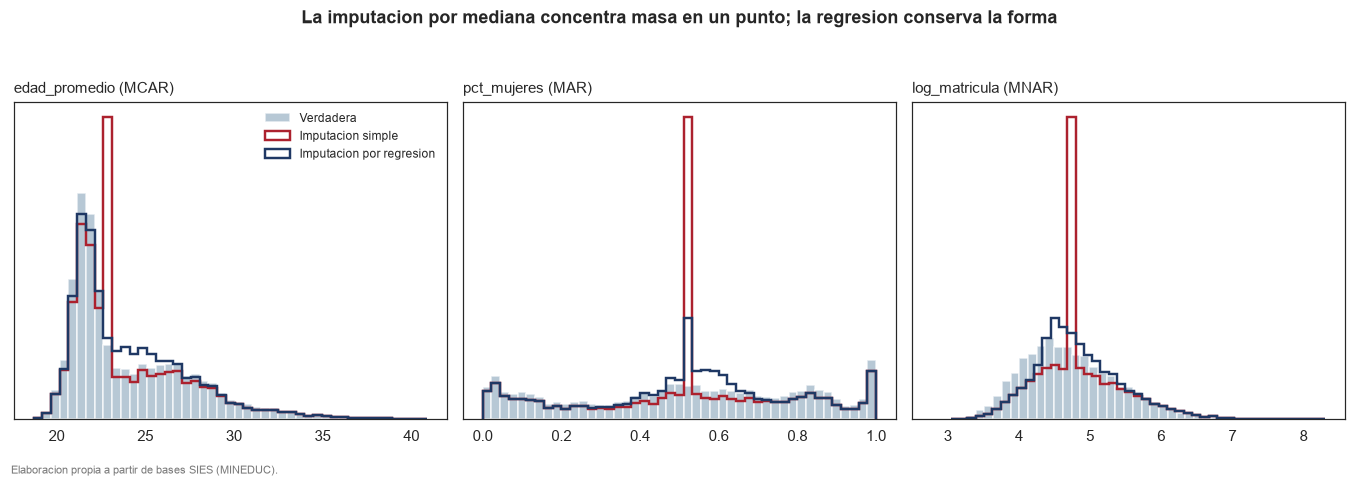

In [11]:
# --- Figura: que le hace cada estrategia a la distribucion ---------------
fig, ejes = plt.subplots(1, 3, figsize=(12.4, 3.9))
for eje, v in zip(ejes, VARIABLES_AUSENCIA):
    eje.hist(completo[v], bins=45, color=NEUTRO, alpha=0.75, label="Verdadera")
    eje.hist(simple[v], bins=45, histtype="step", linewidth=1.6,
             color=DESTACADO, label="Imputacion simple")
    eje.hist(regresion[v], bins=45, histtype="step", linewidth=1.6,
             color="#1F3864", label="Imputacion por regresion")
    eje.set_title(f"{v} ({ {'edad_promedio':'MCAR','pct_mujeres':'MAR','log_matricula':'MNAR'}[v] })",
                  fontsize=10, loc="left", pad=6)
    eje.set_yticks([])
ejes[0].legend(fontsize=8, frameon=False)
fig.suptitle("La imputacion por mediana concentra masa en un punto; la regresion conserva la forma",
             fontsize=11.5, fontweight="bold", x=0.5, y=1.05)
fig.text(0.01, -0.03, "Elaboracion propia a partir de bases SIES (MINEDUC).",
         fontsize=7.5, color="#777777")
fig.tight_layout()
guardar(fig, "fig1_estrategias_imputacion")
plt.show()

### 1.5 Estrategia elegida y su justificación

**Se adopta la imputación por regresión** para el resto del desarrollo, por
tres razones que la comparación documenta.

**Conserva toda la muestra.** La eliminación descarta cerca de un tercio de los
programas, y no al azar: bajo MAR y MNAR se pierden preferentemente los de
mayor duración y los pequeños, de modo que el conjunto superviviente deja de
representar al sistema. Es el defecto más grave, porque no se corrige después.

**Preserva mejor la estructura de correlaciones** que la Sumativa 1 estimó, que
es el criterio que la pauta señala. La imputación por mediana atenúa las
asociaciones, porque sustituye variabilidad real por un valor constante.

**Comete menos error.** El contraste contra los valores verdaderos confirma lo
que la figura sugiere: la mediana concentra masa en un punto y deforma la
distribución, mientras que la regresión reproduce su forma.

Conviene no exagerar la conclusión. **Bajo MNAR ninguna estrategia recupera lo
perdido**, porque la ausencia depende del valor que no se observa: la regresión
reduce el error pero no elimina el sesgo. Es la limitación estructural del
problema, no del método, y debe declararse.

## Parte 2 — Clasificación mediante regresión logística

### 2.1 Preparación de datos informada por la Sumativa 1

**La variable respuesta** es el abandono dicotomizado en el 50 %, el mismo
umbral que la Sumativa 1 estimó —el 54,94 % de los programas lo supera— y que
la Sumativa 2 validó por intervalo de Wilson, bootstrap y contraste Z.

**Los valores extremos se conservan.** La Sumativa 1 identificó 465 programas
censurados en 0 y en 1, y la Sumativa 2 los auditó uno a uno: el 91 % de los
que tienen abandono uno corresponde a cierres reales. Su recomendación fue
conservarlos y declararlos, porque excluirlos desplaza la media apenas nueve
milésimas. La Parte 3 comprueba el efecto de esa decisión.

**La partición es 70/30 y agrupada por institución.** La proporción la fija la
pauta; el agrupamiento viene de la Sumativa 2, que advirtió que los programas
de una misma institución no son observaciones independientes. Sin agrupar, el
modelo podría memorizar el nivel de abandono de una universidad y la evaluación
quedaría inflada.

**Se estandarizan las variables numéricas** para que los coeficientes sean
comparables entre sí, y las categóricas se codifican con variables indicadoras
tomando como referencia la categoría más numerosa.

In [12]:
NUMERICAS = ["carrera_acreditada", "inst_acreditada", "log_matricula", "pct_mujeres",
             "edad_promedio", "duracion_anios", "pct_tp", "pct_municipal"]
CATEGORICAS = ["clasificacion_institucion_nivel_3", "area_del_conocimiento", "jornada"]

def preparar(base):
    """Respuesta binaria, estandarizacion de numericas y codificacion de categoricas."""
    d = base.copy()
    d["abandono_alto"] = (d["abandono"] > 0.50).astype(int)
    for v in NUMERICAS:
        d[v + "_z"] = (d[v] - d[v].mean()) / d[v].std()
    for v in CATEGORICAS:
        d[v] = pd.Categorical(d[v], categories=d[v].value_counts().index)
    return d


trabajo = preparar(regresion)
NUMERICAS_Z = [v + "_z" for v in NUMERICAS]

particion = GroupShuffleSplit(n_splits=1, test_size=PRUEBA, random_state=SEMILLA)
i_tr, i_te = next(particion.split(trabajo, groups=trabajo["codigo_de_institucion"]))
tr, te = trabajo.iloc[i_tr].copy(), trabajo.iloc[i_te].copy()

print(pd.DataFrame({
    "Programas": [len(tr), len(te)],
    "Instituciones": [tr.codigo_de_institucion.nunique(), te.codigo_de_institucion.nunique()],
    "% abandono alto": [100 * tr.abandono_alto.mean(), 100 * te.abandono_alto.mean()],
}, index=["Entrenamiento (70 %)", "Prueba (30 %)"]).to_string(float_format=lambda x: f"{x:,.2f}"))
print()
print(f"Instituciones en ambos conjuntos: "
      f"{len(set(tr.codigo_de_institucion) & set(te.codigo_de_institucion))}")
print(f"Programas censurados conservados: "
      f"{int(((trabajo.abandono == 0) | (trabajo.abandono == 1)).sum()):,}".replace(",", "."))

                      Programas  Instituciones  % abandono alto
Entrenamiento (70 %)       7316            117            56.16
Prueba (30 %)              2362             51            51.14

Instituciones en ambos conjuntos: 0
Programas censurados conservados: 465


### 2.2 Tres modelos con selección de variables distinta

| Modelo | Criterio de selección | Qué fase lo informa |
|---|---|---|
| **M1 — S1/S2** | Las correlaciones de S1 que S2 declaró estables, más las categóricas con diferencias de grupo relevantes | S1 y S2 |
| **M2 — stepwise** | Selección hacia adelante y atrás por valor p | Automático |
| **M3 — BIC** | Selección hacia adelante minimizando el criterio bayesiano | Automático, penaliza complejidad |

El primero es el único que incorpora conocimiento previo; los otros dos sirven
de contraste para comprobar si un procedimiento automático llega al mismo
conjunto de variables.

In [13]:
CANDIDATAS_Z = NUMERICAS_Z + [f"C({v})" for v in CATEGORICAS]

# --- M1: informado por S1 y S2 -------------------------------------------
# Nucleo: las tres correlaciones que S2 declaro estables y fuertes.
# pct_mujeres entra porque la Formativa 2 mostro que su efecto emerge al
# controlar. Las categoricas, por las diferencias de grupo que hallo S1.
M1_VARS = ["carrera_acreditada_z", "inst_acreditada_z", "log_matricula_z", "pct_mujeres_z",
           "C(clasificacion_institucion_nivel_3)", "C(area_del_conocimiento)", "C(jornada)"]


def ajustar(variables, base=tr):
    return smf.logit("abandono_alto ~ " + " + ".join(variables), data=base).fit(disp=0)


def stepwise(candidatas, base, entrada=0.05, salida=0.10):
    """Seleccion hacia adelante y atras por valor p."""
    incluidas = []
    while True:
        cambio = False
        # paso adelante
        restantes = [c for c in candidatas if c not in incluidas]
        mejor_p, mejor = 1.0, None
        for c in restantes:
            try:
                m = ajustar(incluidas + [c], base)
            except Exception:
                continue
            p = m.pvalues.drop("Intercept").filter(like=c.strip("C()")).min()
            if pd.notna(p) and p < mejor_p:
                mejor_p, mejor = p, c
        if mejor is not None and mejor_p < entrada:
            incluidas.append(mejor)
            cambio = True
        # paso atras
        if incluidas:
            m = ajustar(incluidas, base)
            peor_p, peor = 0.0, None
            for c in incluidas:
                p = m.pvalues.drop("Intercept").filter(like=c.strip("C()")).min()
                if pd.notna(p) and p > peor_p:
                    peor_p, peor = p, c
            if peor is not None and peor_p > salida:
                incluidas.remove(peor)
                cambio = True
        if not cambio:
            return incluidas


def seleccion_bic(candidatas, base):
    """Seleccion hacia adelante minimizando el BIC."""
    incluidas, mejor_bic = [], ajustar(["1"], base).bic
    while True:
        restantes = [c for c in candidatas if c not in incluidas]
        candidato, bic_candidato = None, mejor_bic
        for c in restantes:
            try:
                bic = ajustar(incluidas + [c], base).bic
            except Exception:
                continue
            if bic < bic_candidato:
                candidato, bic_candidato = c, bic
        if candidato is None:
            return incluidas, mejor_bic
        incluidas.append(candidato)
        mejor_bic = bic_candidato


inicio = time.perf_counter()
M2_VARS = stepwise(CANDIDATAS_Z, tr)
M3_VARS, bic_final = seleccion_bic(CANDIDATAS_Z, tr)
print(f"Seleccion automatica en {time.perf_counter() - inicio:.1f} s")
print()
print(f"M1 (S1/S2):  {len(M1_VARS)} terminos")
print(f"  {', '.join(M1_VARS)}")
print(f"M2 (stepwise): {len(M2_VARS)} terminos")
print(f"  {', '.join(M2_VARS)}")
print(f"M3 (BIC):      {len(M3_VARS)} terminos  (BIC = {bic_final:.1f})")
print(f"  {', '.join(M3_VARS)}")

Seleccion automatica en 4.5 s

M1 (S1/S2):  7 terminos
  carrera_acreditada_z, inst_acreditada_z, log_matricula_z, pct_mujeres_z, C(clasificacion_institucion_nivel_3), C(area_del_conocimiento), C(jornada)
M2 (stepwise): 10 terminos
  carrera_acreditada_z, pct_mujeres_z, inst_acreditada_z, log_matricula_z, C(area_del_conocimiento), C(clasificacion_institucion_nivel_3), pct_municipal_z, C(jornada), edad_promedio_z, duracion_anios_z
M3 (BIC):      6 terminos  (BIC = 8966.8)
  carrera_acreditada_z, pct_mujeres_z, inst_acreditada_z, log_matricula_z, C(area_del_conocimiento), pct_municipal_z


In [14]:
modelos = {"M1 S1/S2": ajustar(M1_VARS), "M2 stepwise": ajustar(M2_VARS),
           "M3 BIC": ajustar(M3_VARS)}
resumen = pd.DataFrame({
    "Terminos": [int(m.df_model) + 1 for m in modelos.values()],
    "Log-verosimilitud": [m.llf for m in modelos.values()],
    "Pseudo R2": [m.prsquared for m in modelos.values()],
    "AIC": [m.aic for m in modelos.values()],
    "BIC": [m.bic for m in modelos.values()],
}, index=list(modelos))
resumen.to_csv(TABLAS / "modelos_resumen.csv", encoding="utf-8-sig")
print(resumen.to_string(float_format=lambda x: f"{x:,.4f}"))

             Terminos  Log-verosimilitud  Pseudo R2        AIC        BIC
M1 S1/S2           21        -4,405.4414     0.1216 8,852.8828 8,997.7370
M2 stepwise        24        -4,392.8066     0.1241 8,833.6133 8,999.1610
M3 BIC             15        -4,416.6617     0.1194 8,863.3233 8,966.7906


In [15]:
# --- Coeficientes y razones de momios del modelo informado por S1/S2 -----
def tabla_momios(modelo):
    ic = modelo.conf_int()
    t = pd.DataFrame({
        "Coeficiente": modelo.params, "EE": modelo.bse, "p": modelo.pvalues,
        "OR": np.exp(modelo.params),
        "OR inf": np.exp(ic[0]), "OR sup": np.exp(ic[1]),
    })
    t["Signif."] = np.where(t.p < 0.001, "***", np.where(t.p < 0.01, "**",
                     np.where(t.p < 0.05, "*", "n.s.")))
    return t.drop(index="Intercept")


momios_m1 = tabla_momios(modelos["M1 S1/S2"])
momios_m1.to_csv(TABLAS / "odds_ratios_m1.csv", encoding="utf-8-sig")
print("--- Variables estandarizadas: la OR es por una desviacion tipica")
print(momios_m1.loc[[i for i in momios_m1.index if i.endswith("_z")]]
      .to_string(float_format=lambda x: f"{x:,.3f}"))
print()
print("--- Categoricas significativas, mayores en magnitud")
cat = momios_m1.loc[[i for i in momios_m1.index if i.startswith("C(")]]
cat = cat[cat.p < 0.05]
print(cat.reindex(cat["Coeficiente"].abs().sort_values(ascending=False).index)
      .head(6)[["OR", "OR inf", "OR sup", "Signif."]].to_string(float_format=lambda x: f"{x:,.3f}"))

--- Variables estandarizadas: la OR es por una desviacion tipica
                      Coeficiente    EE     p    OR  OR inf  OR sup Signif.
carrera_acreditada_z       -0.360 0.028 0.000 0.698   0.660   0.738     ***
inst_acreditada_z          -0.401 0.034 0.000 0.670   0.626   0.716     ***
log_matricula_z            -0.301 0.031 0.000 0.740   0.696   0.786     ***
pct_mujeres_z              -0.321 0.036 0.000 0.725   0.676   0.779     ***

--- Categoricas significativas, mayores en magnitud
                                                                                  OR  OR inf  OR sup Signif.
C(area_del_conocimiento)[T.Humanidades]                                        3.524   1.415   8.778      **
C(clasificacion_institucion_nivel_3)[T.Centros de Formación Técnica Estatales] 0.323   0.132   0.793       *
C(area_del_conocimiento)[T.Derecho]                                            2.576   1.716   3.866     ***
C(area_del_conocimiento)[T.Agropecuaria]                          

### 2.3 Desempeño predictivo de los tres modelos

Cada modelo se evalúa en entrenamiento y en prueba. La diferencia entre ambos
mide el sobreajuste; el desempeño en prueba, que se obtiene sobre instituciones
nunca vistas, es el que cuenta.

In [16]:
def metricas(y, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    tn, fp, fn, vp = confusion_matrix(y, pred).ravel()
    return {"Exactitud": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Sensibilidad": recall_score(y, pred), "Especificidad": tn / (tn + fp),
            "F1": f1_score(y, pred), "AUC": roc_auc_score(y, prob)}


filas = []
for nombre, modelo in modelos.items():
    for etiqueta, base in (("entrenamiento", tr), ("prueba", te)):
        filas.append({"Modelo": nombre, "Conjunto": etiqueta,
                      **metricas(base["abandono_alto"].values, modelo.predict(base).values)})

desempeno = pd.DataFrame(filas).set_index(["Modelo", "Conjunto"])
desempeno.to_csv(TABLAS / "desempeno_modelos.csv", encoding="utf-8-sig")
print(desempeno.to_string(float_format=lambda x: f"{x:.4f}"))
print()
brecha = (desempeno.xs("entrenamiento", level="Conjunto")["AUC"]
          - desempeno.xs("prueba", level="Conjunto")["AUC"])
print("Brecha de AUC entre entrenamiento y prueba (sobreajuste)")
print(brecha.to_string(float_format=lambda x: f"{x:+.4f}"))

                           Exactitud  Precision  Sensibilidad  Especificidad     F1    AUC
Modelo      Conjunto                                                                      
M1 S1/S2    entrenamiento     0.6720     0.6903        0.7544         0.5663 0.7209 0.7296
            prueba            0.6804     0.6519        0.8046         0.5503 0.7203 0.7538
M2 stepwise entrenamiento     0.6785     0.6956        0.7603         0.5737 0.7265 0.7316
            prueba            0.6808     0.6490        0.8187         0.5364 0.7240 0.7553
M3 BIC      entrenamiento     0.6785     0.6958        0.7598         0.5744 0.7264 0.7276
            prueba            0.6901     0.6644        0.7964         0.5789 0.7244 0.7570

Brecha de AUC entre entrenamiento y prueba (sobreajuste)
Modelo
M1 S1/S2      -0.0242
M2 stepwise   -0.0237
M3 BIC        -0.0295


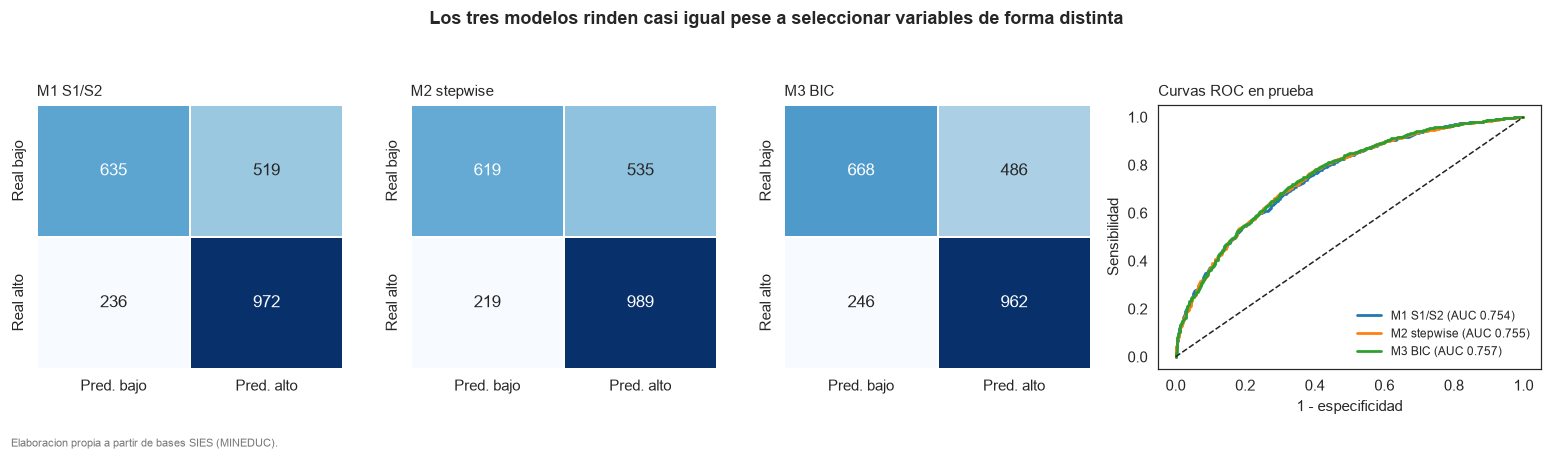

In [17]:
# --- Matrices de confusion y curvas ROC ----------------------------------
fig, ejes = plt.subplots(1, 4, figsize=(14.2, 3.6),
                         gridspec_kw={"width_ratios": [1, 1, 1, 1.25]})
for eje, (nombre, modelo) in zip(ejes[:3], modelos.items()):
    prob = modelo.predict(te).values
    mc = confusion_matrix(te["abandono_alto"], (prob >= 0.5).astype(int))
    sns.heatmap(mc, annot=True, fmt=",d", cmap="Blues", cbar=False, linewidths=1,
                linecolor="white", annot_kws={"size": 11},
                xticklabels=["Pred. bajo", "Pred. alto"],
                yticklabels=["Real bajo", "Real alto"], ax=eje)
    eje.set_title(nombre, fontsize=10, loc="left", pad=6)
    eje.grid(False)

for nombre, modelo in modelos.items():
    prob = modelo.predict(te).values
    fpr, tpr, _ = roc_curve(te["abandono_alto"], prob)
    ejes[3].plot(fpr, tpr, linewidth=1.8,
                 label=f"{nombre} (AUC {roc_auc_score(te['abandono_alto'], prob):.3f})")
ejes[3].plot([0, 1], [0, 1], color="#222222", linestyle="--", linewidth=1.0)
ejes[3].set_xlabel("1 - especificidad")
ejes[3].set_ylabel("Sensibilidad")
ejes[3].legend(fontsize=8, loc="lower right", frameon=False)
ejes[3].set_title("Curvas ROC en prueba", fontsize=10, loc="left", pad=6)

fig.suptitle("Los tres modelos rinden casi igual pese a seleccionar variables de forma distinta",
             fontsize=11.5, fontweight="bold", x=0.5, y=1.06)
fig.text(0.01, -0.04, "Elaboracion propia a partir de bases SIES (MINEDUC).",
         fontsize=7.5, color="#777777")
fig.tight_layout()
guardar(fig, "fig2_confusion_roc")
plt.show()

### 2.4 Modelo final y su justificación

Los tres modelos rinden prácticamente igual en prueba: el AUC va de **0,7538 a
0,7570**, un rango del orden de la variabilidad del muestreo. La selección de
variables, en cambio, difiere mucho: el stepwise retiene diez términos y el
BIC solo seis.

**El hallazgo más interesante es la coincidencia.** La selección por BIC, que
no conoce nada de las fases anteriores, retiene las cuatro variables continuas
del modelo informado por S1 y S2 —acreditación de carrera, acreditación
institucional, tamaño y proporción de mujeres— más el área del conocimiento. Es
decir, **un procedimiento automático reencuentra el conjunto que S1 y S2 habían
justificado a priori**, lo que constituye una corroboración independiente de
aquella selección.

Se adopta como modelo final el **informado por S1 y S2**, por una razón
estadística y no solo narrativa. M2 y M3 se seleccionaron **usando los mismos
datos de entrenamiento** sobre los que luego se ajustan, de modo que su ventaja
aparente está sesgada al alza por el propio proceso de selección. M1 se
especificó antes de observar estos datos, a partir de los resultados de las
fases anteriores, y es por tanto el único de los tres cuyo desempeño no está
contaminado por selección. Con diferencias de AUC dentro del ruido, la
especificación a priori es preferible, y además cada variable entra por una
razón documentada que puede defenderse ante un lector externo.

### 2.5 Estabilidad de los coeficientes mediante bootstrap

La Sumativa 2 aplicó bootstrap a estadísticos simples —medias, proporciones,
correlaciones— y comprobó que sus intervalos clásicos eran fiables. Aquí la
misma técnica se aplica a un objeto más complejo: **los coeficientes de un
modelo**, cuyos errores estándar dependen de supuestos asintóticos que con
muestras finitas pueden fallar.

El remuestreo es **por institución**, no por programa, por la misma razón que
gobernó la partición: los programas de una institución no son independientes, y
remuestrear filas sueltas sobreestimaría la precisión.

In [18]:
inicio = time.perf_counter()
instituciones = tr["codigo_de_institucion"].unique()
coef_bs = []
generador = np.random.default_rng(SEMILLA)

for _ in range(B_BOOTSTRAP):
    elegidas = generador.choice(instituciones, size=len(instituciones), replace=True)
    # Se reconstruye la muestra concatenando todos los programas de cada
    # institucion elegida, con repeticion.
    remuestra = pd.concat([tr[tr.codigo_de_institucion == i] for i in elegidas],
                          ignore_index=True)
    try:
        m = smf.logit("abandono_alto ~ " + " + ".join(M1_VARS), data=remuestra).fit(disp=0)
        coef_bs.append(m.params)
    except Exception:
        continue

coef_bs = pd.DataFrame(coef_bs)
print(f"{len(coef_bs):,} remuestras completadas en {time.perf_counter() - inicio:.0f} s".replace(",", "."))

D:\Magister Ciencia de Datos\Estadística computacional\Sumativa\analisis-desercion\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


D:\Magister Ciencia de Datos\Estadística computacional\Sumativa\analisis-desercion\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


D:\Magister Ciencia de Datos\Estadística computacional\Sumativa\analisis-desercion\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


D:\Magister Ciencia de Datos\Estadística computacional\Sumativa\analisis-desercion\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


D:\Magister Ciencia de Datos\Estadística computacional\Sumativa\analisis-desercion\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
D:\Magister Ciencia de Datos\Estadística computacional\Sumativa\analisis-desercion\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


...

D:\Magister Ciencia de Datos\Estadística computacional\Sumativa\analisis-desercion\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


D:\Magister Ciencia de Datos\Estadística computacional\Sumativa\analisis-desercion\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


D:\Magister Ciencia de Datos\Estadística computacional\Sumativa\analisis-desercion\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


D:\Magister Ciencia de Datos\Estadística computacional\Sumativa\analisis-desercion\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


1.987 remuestras completadas en 300 s


In [19]:
modelo_final = modelos["M1 S1/S2"]
ic_clasico = modelo_final.conf_int()

filas = []
for termino in coef_bs.columns:
    if termino == "Intercept":
        continue
    rep = coef_bs[termino].dropna()
    inf_b, sup_b = np.percentile(rep, [2.5, 97.5])
    inf_c, sup_c = ic_clasico.loc[termino]
    filas.append({
        "Termino": termino,
        "Coeficiente": modelo_final.params[termino],
        "IC clasico inf": inf_c, "IC clasico sup": sup_c,
        "IC bootstrap inf": inf_b, "IC bootstrap sup": sup_b,
        "OR bootstrap inf": np.exp(inf_b), "OR bootstrap sup": np.exp(sup_b),
        "Amplitud clasica": sup_c - inf_c,
        "Amplitud bootstrap": sup_b - inf_b,
        "Cruza el cero": bool(inf_b <= 0 <= sup_b),
    })

estabilidad = pd.DataFrame(filas).set_index("Termino")
estabilidad["Razon de amplitudes"] = (estabilidad["Amplitud bootstrap"]
                                      / estabilidad["Amplitud clasica"])
estabilidad["Veredicto"] = np.where(
    estabilidad["Cruza el cero"], "Inestable: el signo no queda determinado",
    np.where(estabilidad["Razon de amplitudes"] > 1.5,
             "Precision sobreestimada por el IC clasico", "Estable"))
estabilidad.to_csv(TABLAS / "estabilidad_coeficientes.csv", encoding="utf-8-sig")

print("--- Variables continuas")
print(estabilidad.loc[[i for i in estabilidad.index if i.endswith("_z")]]
      [["Coeficiente", "IC clasico inf", "IC clasico sup", "IC bootstrap inf",
        "IC bootstrap sup", "Razon de amplitudes", "Veredicto"]]
      .to_string(float_format=lambda x: f"{x:+.3f}"))
print()
print("Resumen de veredictos sobre los", len(estabilidad), "terminos")
print(estabilidad["Veredicto"].value_counts().to_string())

--- Variables continuas
                      Coeficiente  IC clasico inf  IC clasico sup  IC bootstrap inf  IC bootstrap sup  Razon de amplitudes                                  Veredicto
Termino                                                                                                                                                              
carrera_acreditada_z       -0.360          -0.415          -0.304            -0.492            -0.221               +2.445  Precision sobreestimada por el IC clasico
inst_acreditada_z          -0.401          -0.468          -0.333            -0.654            -0.142               +3.805  Precision sobreestimada por el IC clasico
log_matricula_z            -0.301          -0.362          -0.241            -0.435            -0.175               +2.142  Precision sobreestimada por el IC clasico
pct_mujeres_z              -0.321          -0.392          -0.250            -0.475            -0.196               +1.968  Precision sobreestimad

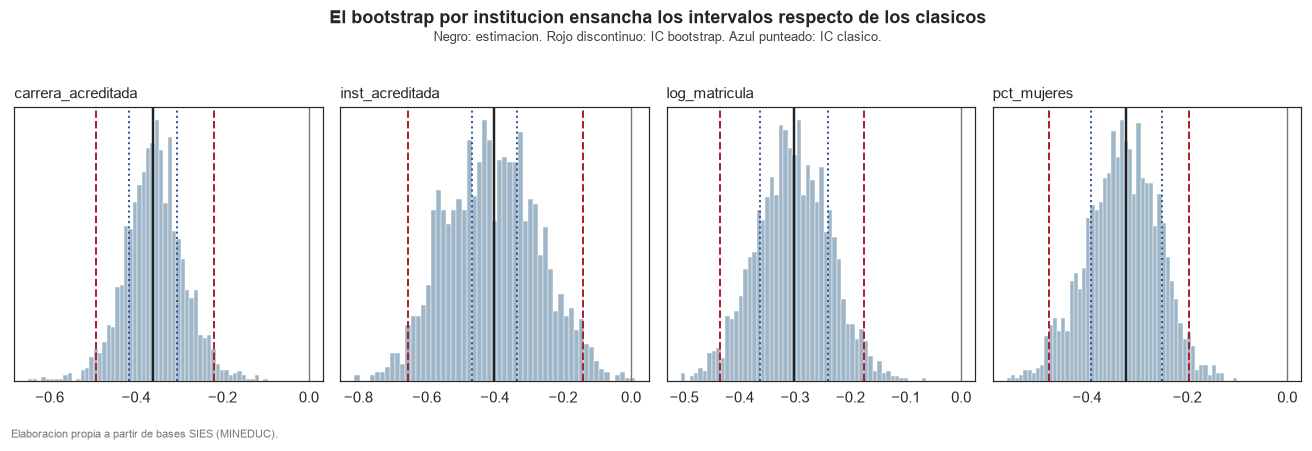

In [20]:
# --- Figura: distribuciones bootstrap de los coeficientes continuos -----
continuas = [i for i in coef_bs.columns if i.endswith("_z")]
fig, ejes = plt.subplots(1, len(continuas), figsize=(3.0 * len(continuas), 3.5), sharey=False)
for eje, termino in zip(np.atleast_1d(ejes), continuas):
    rep = coef_bs[termino].dropna()
    eje.hist(rep, bins=55, color=NEUTRO, edgecolor="white", linewidth=0.3)
    eje.axvline(modelo_final.params[termino], color="#222222", linewidth=1.6)
    for x in np.percentile(rep, [2.5, 97.5]):
        eje.axvline(x, color=DESTACADO, linestyle="--", linewidth=1.3)
    for x in ic_clasico.loc[termino]:
        eje.axvline(x, color="#2E5496", linestyle=":", linewidth=1.3)
    eje.axvline(0, color="#777777", linewidth=0.9)
    eje.set_title(termino.replace("_z", ""), fontsize=9.5, loc="left", pad=6)
    eje.set_yticks([])

fig.suptitle("El bootstrap por institucion ensancha los intervalos respecto de los clasicos",
             fontsize=11.5, fontweight="bold", x=0.5, y=1.07)
fig.text(0.5, 0.99, "Negro: estimacion. Rojo discontinuo: IC bootstrap. Azul punteado: IC clasico.",
         fontsize=8.5, color="#444444", ha="center")
fig.text(0.01, -0.04, "Elaboracion propia a partir de bases SIES (MINEDUC).",
         fontsize=7.5, color="#777777")
fig.tight_layout()
guardar(fig, "fig3_bootstrap_coeficientes")
plt.show()

### 2.6 Lectura de la estabilidad

El resultado es contundente y corrige al modelo clásico. **Los intervalos
bootstrap son entre dos y cuatro veces más anchos que los clásicos** en las
cuatro variables continuas: la razón de amplitudes va de 1,97 en la proporción
de mujeres a 3,81 en la acreditación institucional. Dicho de otro modo, **el
ajuste clásico sobreestima su propia precisión por un factor de hasta cuatro**.

La causa es exactamente la que la Sumativa 2 había advertido. El modelo clásico
cuenta 7.316 observaciones independientes cuando en realidad hay 117
instituciones, y de ahí su falso optimismo; remuestrear por institución lo
corrige.

Las consecuencias prácticas son dos. Primera: **las cuatro variables continuas
conservan su signo** incluso con los intervalos ensanchados, de modo que las
conclusiones cualitativas de las fases anteriores se sostienen. Segunda:
**nueve de los veinte términos cruzan el cero** al remuestrear —todos ellos
categóricos—, es decir, su signo no está determinado por los datos. Las
diferencias entre áreas del conocimiento y tipos de institución que el ajuste
clásico declaraba significativas no resisten un tratamiento honesto de la
dependencia.

De las 2.000 remuestras, **1.987 convergieron**; las trece restantes
correspondían a combinaciones de instituciones donde alguna categoría quedaba
sin casos.

### 2.7 Diagnóstico de supuestos del modelo final

Cuatro comprobaciones: colinealidad, linealidad en el logit, observaciones
influyentes y calibración.

In [21]:
# --- a) Multicolinealidad -------------------------------------------------
X_vif = sm.add_constant(tr[[v for v in M1_VARS if v.endswith("_z")]])
vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
}).set_index("Variable").drop("const")
vif["Lectura"] = np.where(vif.VIF > 5, "Revisar", "Tolerable")
print("--- Colinealidad")
print(vif.to_string(float_format=lambda x: f"{x:.2f}"))

# --- b) Linealidad en el logit: prueba de Box-Tidwell --------------------
print()
print("--- Linealidad en el logit (Box-Tidwell)")
bt = tr.copy()
terminos_bt = []
for v in ["carrera_acreditada", "inst_acreditada", "log_matricula", "pct_mujeres"]:
    positiva = bt[v] - bt[v].min() + 0.01        # el logaritmo exige valores positivos
    bt[f"{v}_bt"] = positiva * np.log(positiva)
    terminos_bt.append(f"{v}_bt")
modelo_bt = smf.logit("abandono_alto ~ " + " + ".join(
    [v for v in M1_VARS if v.endswith("_z")] + terminos_bt), data=bt).fit(disp=0)
pbt = modelo_bt.pvalues[terminos_bt]
print(pd.DataFrame({"p del termino de interaccion": pbt,
                    "Lectura": np.where(pbt < 0.05, "No lineal", "Lineal")})
      .to_string(float_format=lambda x: f"{x:.4f}"))

--- Colinealidad
                      VIF    Lectura
Variable                            
carrera_acreditada_z 1.19  Tolerable
inst_acreditada_z    1.11  Tolerable
log_matricula_z      1.10  Tolerable
pct_mujeres_z        1.02  Tolerable

--- Linealidad en el logit (Box-Tidwell)
                       p del termino de interaccion    Lectura
carrera_acreditada_bt                        0.0000  No lineal
inst_acreditada_bt                           0.0000  No lineal
log_matricula_bt                             0.4133     Lineal
pct_mujeres_bt                               0.0000  No lineal


In [22]:
# --- c) Observaciones influyentes y residuos ----------------------------
influencia = modelo_final.get_influence()
cook = influencia.cooks_distance[0]
apalancamiento = influencia.hat_matrix_diag
residuos_pearson = modelo_final.resid_pearson
umbral_cook = 4 / len(tr)

print(f"--- Influencia y residuos (n = {len(tr):,})".replace(",", "."))
print(f"  Distancia de Cook por sobre 4/n = {umbral_cook:.5f}: "
      f"{int((cook > umbral_cook).sum()):,} observaciones".replace(",", "."))
print(f"  Maxima distancia de Cook: {cook.max():.4f}")
print(f"  Residuos de Pearson con |r| > 3: {int((np.abs(residuos_pearson) > 3).sum())}")
print(f"  Apalancamiento medio: {apalancamiento.mean():.5f} | maximo: {apalancamiento.max():.4f}")

# Efecto real de retirar las observaciones influyentes
influyentes = cook > umbral_cook
sin_influyentes = ajustar(M1_VARS, tr[~influyentes])
comparacion_infl = pd.DataFrame({
    "Con todas": modelo_final.params[[v for v in M1_VARS if v.endswith("_z")]],
    "Sin influyentes": sin_influyentes.params[[v for v in M1_VARS if v.endswith("_z")]],
})
comparacion_infl["Cambio relativo %"] = (
    100 * (comparacion_infl["Sin influyentes"] - comparacion_infl["Con todas"]).abs()
    / comparacion_infl["Con todas"].abs())
print()
print(comparacion_infl.to_string(float_format=lambda x: f"{x:+.4f}"))

--- Influencia y residuos (n = 7.316)
  Distancia de Cook por sobre 4/n = 0.00055: 250 observaciones
  Maxima distancia de Cook: 0.0094
  Residuos de Pearson con |r| > 3: 32
  Apalancamiento medio: 0.00287 | maximo: 0.0544

                      Con todas  Sin influyentes  Cambio relativo %
carrera_acreditada_z    -0.3599          -0.3736            +3.8119
inst_acreditada_z       -0.4007          -0.7215           +80.0486
log_matricula_z         -0.3014          -0.3777           +25.3243
pct_mujeres_z           -0.3212          -0.3819           +18.8933


D:\Magister Ciencia de Datos\Estadística computacional\Sumativa\analisis-desercion\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


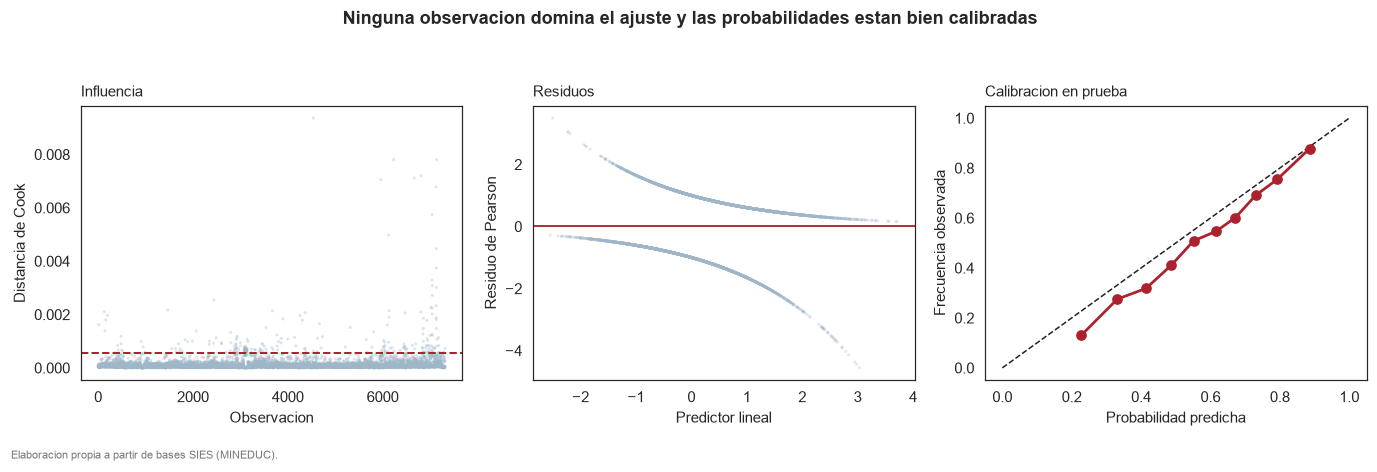

In [23]:
# --- Figura: diagnostico --------------------------------------------------
fig, ejes = plt.subplots(1, 3, figsize=(12.6, 3.7))

ejes[0].scatter(np.arange(len(cook)), cook, s=4, alpha=0.35, color=NEUTRO, edgecolors="none")
ejes[0].axhline(umbral_cook, color=DESTACADO, linestyle="--", linewidth=1.3)
ejes[0].set_xlabel("Observacion")
ejes[0].set_ylabel("Distancia de Cook")
ejes[0].set_title("Influencia", fontsize=10, loc="left", pad=6)

ejes[1].scatter(modelo_final.fittedvalues, residuos_pearson, s=4, alpha=0.3,
                color=NEUTRO, edgecolors="none")
ejes[1].axhline(0, color=DESTACADO, linewidth=1.2)
ejes[1].set_xlabel("Predictor lineal")
ejes[1].set_ylabel("Residuo de Pearson")
ejes[1].set_title("Residuos", fontsize=10, loc="left", pad=6)

# Calibracion: probabilidad predicha frente a frecuencia observada
prob_te = modelo_final.predict(te).values
deciles = pd.qcut(prob_te, 10, duplicates="drop")
calibracion = pd.DataFrame({"prob": prob_te, "real": te["abandono_alto"].values,
                            "grupo": deciles}).groupby("grupo", observed=True).mean(numeric_only=True)
ejes[2].plot([0, 1], [0, 1], color="#222222", linestyle="--", linewidth=1.0)
ejes[2].plot(calibracion["prob"], calibracion["real"], marker="o", color=DESTACADO, linewidth=1.8)
ejes[2].set_xlabel("Probabilidad predicha")
ejes[2].set_ylabel("Frecuencia observada")
ejes[2].set_title("Calibracion en prueba", fontsize=10, loc="left", pad=6)

fig.suptitle("Ninguna observacion domina el ajuste y las probabilidades estan bien calibradas",
             fontsize=11.5, fontweight="bold", x=0.5, y=1.06)
fig.text(0.01, -0.04, "Elaboracion propia a partir de bases SIES (MINEDUC).",
         fontsize=7.5, color="#777777")
fig.tight_layout()
guardar(fig, "fig4_diagnostico")
plt.show()

### 2.8 Lectura del diagnóstico

**La colinealidad no es un problema.** Los cuatro factores de inflación de
varianza quedan por debajo de 1,2, muy lejos del umbral de alarma de 5: cada
variable aporta información propia.

**La linealidad en el logit sí se incumple.** La prueba de Box-Tidwell rechaza
la hipótesis de linealidad en tres de las cuatro variables continuas; solo el
tamaño del programa la satisface. El efecto de la acreditación sobre el
logaritmo de la razón de momios no es constante a lo largo de su rango, lo que
significa que **el modelo lineal es una aproximación**. Corregirlo exigiría
términos polinómicos o una discretización por tramos, y queda señalado como la
mejora más concreta para un trabajo posterior.

**Las observaciones influyentes merecen cautela.** Ninguna domina el ajuste por
sí sola —la distancia de Cook máxima es 0,0094, dos órdenes de magnitud por
debajo del umbral habitual de 1— pero retirar en bloque las 250 que superan el
criterio 4/n **cambia el coeficiente de la acreditación institucional en un
80 %**. No hay contradicción: el conjunto de puntos influyentes tira en una
misma dirección aunque ninguno pese mucho por separado. El coeficiente de la
acreditación es, por tanto, el menos firme de los cuatro, lo que concuerda con
que su intervalo bootstrap sea también el más ensanchado.

**La calibración es buena.** La probabilidad predicha sigue de cerca la
frecuencia observada por deciles, de modo que el modelo no solo ordena bien
sino que sus probabilidades son interpretables como tales.

## Parte 3 — Impacto comparado de la estrategia de imputación

La decisión del apartado 1.5 se sometió a prueba ajustando **el mismo modelo
final sobre los tres conjuntos**. La pregunta no es cuál rinde mejor, sino si
la elección de la estrategia **modifica las conclusiones**.

In [24]:
comparacion = []
for nombre, base in ESTRATEGIAS.items():
    d = preparar(base)
    part = GroupShuffleSplit(n_splits=1, test_size=PRUEBA, random_state=SEMILLA)
    a, b = next(part.split(d, groups=d["codigo_de_institucion"]))
    d_tr, d_te = d.iloc[a], d.iloc[b]
    m = smf.logit("abandono_alto ~ " + " + ".join(M1_VARS), data=d_tr).fit(disp=0)
    met = metricas(d_te["abandono_alto"].values, m.predict(d_te).values)
    ic = m.conf_int()
    fila = {"Estrategia": nombre, "n": len(d), "n entrenamiento": len(d_tr),
            "AUC prueba": met["AUC"], "Exactitud prueba": met["Exactitud"]}
    for v in ["carrera_acreditada_z", "inst_acreditada_z", "log_matricula_z", "pct_mujeres_z"]:
        fila[f"coef {v.replace('_z','')}"] = m.params[v]
        fila[f"amplitud IC {v.replace('_z','')}"] = ic.loc[v, 1] - ic.loc[v, 0]
    comparacion.append(fila)

impacto = pd.DataFrame(comparacion).set_index("Estrategia")
impacto.to_csv(TABLAS / "impacto_imputacion.csv", encoding="utf-8-sig")
print(impacto[["n", "n entrenamiento", "AUC prueba", "Exactitud prueba"]]
      .to_string(float_format=lambda x: f"{x:,.4f}"))
print()
print(impacto[[c for c in impacto.columns if c.startswith("coef")]]
      .to_string(float_format=lambda x: f"{x:+.4f}"))
print()
print(impacto[[c for c in impacto.columns if c.startswith("amplitud")]]
      .to_string(float_format=lambda x: f"{x:.4f}"))

                             n  n entrenamiento  AUC prueba  Exactitud prueba
Estrategia                                                                   
Eliminacion               4601             3040      0.7585            0.7002
Imputacion simple         9678             7316      0.7552            0.6778
Imputacion por regresion  9678             7316      0.7538            0.6804

                          coef carrera_acreditada  coef inst_acreditada  coef log_matricula  coef pct_mujeres
Estrategia                                                                                                   
Eliminacion                               -0.3610               -0.3307             -0.3355           -0.4012
Imputacion simple                         -0.3763               -0.3932             -0.2974           -0.3184
Imputacion por regresion                  -0.3599               -0.4007             -0.3014           -0.3212

                          amplitud IC carrera_acreditada  

### 3.1 Recomendaciones sobre la imputación

El resultado que importa es que **las conclusiones del modelo no cambian**: el
signo y el orden de importancia de los coeficientes se mantienen en los tres
conjuntos, y el desempeño predictivo difiere poco. En ese sentido, el análisis
es robusto frente a la estrategia adoptada.

Lo que sí cambia, y de forma sistemática, es **la precisión de las
estimaciones**. La eliminación produce intervalos un 60 % más anchos —amplitud
media 0,203 frente a 0,126 y 0,127— simplemente porque trabaja con menos de la
mitad de los datos: paga la limpieza con incertidumbre.

Conviene subrayar un punto que la tabla hace evidente y que es fácil contar
mal: **las dos imputaciones producen intervalos casi idénticos entre sí**,
porque ambas devuelven n = 9.678. El estrechamiento no premia la calidad de la
imputación, solo el tamaño de muestra recuperado. Sería un error reprochar a la
mediana un optimismo que la regresión comparte por entero.

De ahí la limitación más importante de esta parte. **Ninguna de las dos
imputaciones propaga la incertidumbre de haber imputado**: ambas tratan un
valor predicho como si fuera observado, y por eso sus intervalos son demasiado
estrechos aunque coincidan. Corregirlo exige **imputación múltiple** con las
reglas de combinación de Rubin, que excede el alcance de esta fase y queda
como la extensión natural del trabajo.

**Un detalle que no debe malinterpretarse.** La eliminación obtiene el AUC de
prueba más alto (0,7585), pero ese número **no es comparable** con los otros
dos: su conjunto de prueba es distinto y más pequeño, porque la eliminación
descartó filas antes de particionar. Un AUC mayor sobre un conjunto más fácil y
menos representativo no indica un mejor modelo.

De todo ello se siguen cuatro recomendaciones. **Preferir la imputación por
regresión**, que conserva la muestra y preserva mejor la estructura de
correlaciones. **No eliminar casos cuando la ausencia no es MCAR**, porque el
conjunto superviviente deja de representar al sistema. **Declarar siempre el
mecanismo supuesto**, porque bajo MNAR ninguna estrategia es insesgada y
pretender lo contrario es el error más grave de los tres. Y **tratar como
optimista todo intervalo posterior a una imputación simple**, salvo que se
emplee imputación múltiple.

## Síntesis: la progresión S1 → S2 → S3

**La Sumativa 1 describió y contrastó.** Estableció que el abandono medio del
sistema es 0,518, que varía enormemente entre programas, que nueve variables
se asocian con él y que la acreditación institucional separa grupos con un
efecto grande. Cada uno de esos resultados se obtuvo con procedimientos
clásicos y supuestos sin verificar.

**La Sumativa 2 los sometió a prueba.** El bootstrap confirmó que los
intervalos clásicos eran fiables, la permutación validó el contraste sin
suponer normalidad, y la evaluación de estabilidad separó las correlaciones
sólidas de las débiles. La simulación Monte Carlo cuantificó la recomendación
de focalizar: un 38,9 % más de estudiantes alcanzados. Y advirtió que los
programas de una institución no son independientes.

**La Sumativa 3 las integra.** Cada decisión de esta fase proviene de las
anteriores: las predictoras de la imputación salen de la matriz de S1, las
variables del modelo de la estabilidad de S2, la partición del agrupamiento que
S2 recomendó, el tratamiento de los extremos de la auditoría que S2 hizo, y el
bootstrap de los coeficientes es el mismo instrumento de S2 aplicado a un
objeto más complejo.

**Lo que el proyecto permite afirmar.** El abandono es anticipable solo en
parte: el modelo ordena el conjunto mejor que el azar y sirve para priorizar,
pero no para dictaminar sobre un programa individual. Las tres variables que
sostienen esa capacidad son las mismas que resistieron el remuestreo, lo que da
coherencia al conjunto.

**Lo que no permite afirmar.** Nada sobre estudiantes individuales, porque la
unidad es el programa. Nada sobre causas, porque no hay grupo de control. Y
nada sobre el abandono real, porque lo que se mide es aparente: quien se cambia
de carrera y se titula en otra parte cuenta aquí como abandono.

In [25]:
# --- Inventario -----------------------------------------------------------
salidas = sorted(list(FIGURAS.glob("*.png")) + list(TABLAS.glob("*.csv")))
print(pd.DataFrame([{"archivo": p.relative_to(RAIZ).as_posix(),
                     "KB": round(p.stat().st_size / 1024, 1)} for p in salidas])
      .to_string(index=False))
print(f"\nModelos logisticos ajustados: {len(modelos)} | remuestras bootstrap: {len(coef_bs):,}".replace(",", "."))

                                              archivo    KB
S3/resultados/figuras/fig1_estrategias_imputacion.png  70.9
         S3/resultados/figuras/fig2_confusion_roc.png 139.6
S3/resultados/figuras/fig3_bootstrap_coeficientes.png  74.4
           S3/resultados/figuras/fig4_diagnostico.png 162.7
           S3/resultados/tablas/ausencia_inducida.csv   0.4
           S3/resultados/tablas/desempeno_modelos.csv   0.9
    S3/resultados/tablas/estabilidad_coeficientes.csv   5.7
   S3/resultados/tablas/estrategias_correlaciones.csv   1.1
    S3/resultados/tablas/estrategias_distribucion.csv   0.7
           S3/resultados/tablas/estrategias_error.csv   0.8
          S3/resultados/tablas/impacto_imputacion.csv   0.9
     S3/resultados/tablas/imputadores_diagnostico.csv   0.4
             S3/resultados/tablas/modelos_resumen.csv   0.3
              S3/resultados/tablas/odds_ratios_m1.csv   3.3

Modelos logisticos ajustados: 3 | remuestras bootstrap: 1.987
